# PRAICP-1010: Image Classification on 10 Categories
**Goal:** Classify 10 different object categories.

1. **Without transfer learning**: a CNN built and trained from scratch (with data augmentation).
2. **With transfer learning**: MobileNetV2 pre-trained on ImageNet, 


## 1. Setup

In [2]:
!pip install -q tensorflow scikit-learn seaborn pandas matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install keras



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os, sys, json, zipfile, urllib.request, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (160, 160)
BATCH = 64
EPOCHS_SCRATCH = 20
EPOCHS_HEAD = 5        # transfer learning: train only the new head
EPOCHS_FINE = 10       # transfer learning: fine-tune top of the backbone
AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: []


## 2. Download and locate the dataset

In [2]:
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-1-6/imagenet-subset-10.zip"
DATA_DIR = "data_imagenet10"
ZIP_PATH = DATA_DIR + ".zip"

if not os.path.exists(DATA_DIR):
    print("Downloading dataset ...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Extracted to", DATA_DIR)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

def has_images(d):
    return any(f.lower().endswith(IMG_EXT) for f in os.listdir(d))

def class_dirs(d):
    subs = [s for s in sorted(os.listdir(d)) if os.path.isdir(os.path.join(d, s)) and not s.startswith(("__", "."))]
    return [s for s in subs if has_images(os.path.join(d, s))]

def find_root(d):
    """Walk down until we find a folder that either holds class folders (with images) or train/val/test splits."""
    for _ in range(6):
        subs = [s for s in sorted(os.listdir(d)) if os.path.isdir(os.path.join(d, s)) and not s.startswith(("__", "."))]
        if len(class_dirs(d)) >= 2:
            return d
        low = [s.lower() for s in subs]
        if any(x in low for x in ("train", "training")):
            return d
        if len(subs) == 1:
            d = os.path.join(d, subs[0]); continue
        # several subfolders but none are classes: pick the one that looks like a dataset
        for s in subs:
            cand = os.path.join(d, s)
            if len(class_dirs(cand)) >= 2 or any(x.lower() in ("train", "training") for x in os.listdir(cand)):
                return cand
        break
    return d

ROOT = find_root(DATA_DIR)
print("Dataset root:", ROOT)
print("Contents:", sorted(os.listdir(ROOT)))

Dataset root: data_imagenet10\imagenet subset
Contents: ['desc.txt', 'train', 'val']


## 3. Load data
If the dataset ships with train/validation/test folders they are used as-is; otherwise a 70/15/15 split is created.

Using provided train/val/test directories
Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
Classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
train: 148 batches
val: 31 batches
test: 31 batches


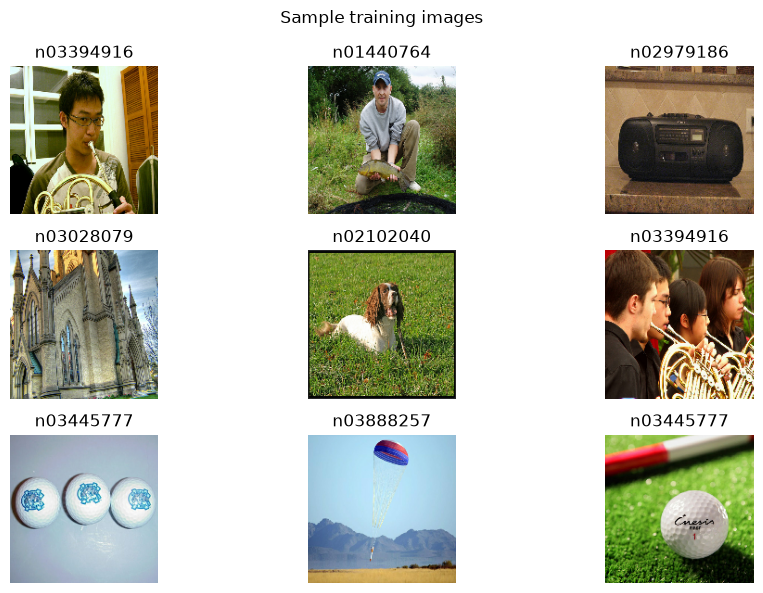

In [3]:
def pick(root, names):
    for s in os.listdir(root):
        if s.lower() in names and os.path.isdir(os.path.join(root, s)):
            return os.path.join(root, s)
    return None

train_dir = pick(ROOT, ("train", "training"))
val_dir   = pick(ROOT, ("val", "valid", "validation"))
test_dir  = pick(ROOT, ("test", "testing"))

def make_ds(path, **kw):
    return keras.utils.image_dataset_from_directory(path, image_size=IMG_SIZE, batch_size=BATCH, label_mode="int", **kw)

if train_dir:
    print("Using provided train/val/test directories")
    train_ds = make_ds(train_dir, shuffle=True, seed=SEED)
    class_names = train_ds.class_names
    if val_dir and test_dir:
        val_ds, test_ds = make_ds(val_dir, shuffle=False), make_ds(test_dir, shuffle=False)
    elif val_dir or test_dir:
        val_ds = make_ds(val_dir or test_dir, shuffle=False)
        half = val_ds.cardinality().numpy() // 2
        test_ds, val_ds = val_ds.take(half), val_ds.skip(half)
    else:
        train_ds = make_ds(train_dir, validation_split=0.3, subset="training", seed=SEED)
        tmp = make_ds(train_dir, validation_split=0.3, subset="validation", seed=SEED, shuffle=False)
        half = tmp.cardinality().numpy() // 2
        test_ds, val_ds = tmp.take(half), tmp.skip(half)
else:
    print("Single folder of classes: creating 70/15/15 split")
    train_ds = make_ds(ROOT, validation_split=0.3, subset="training", seed=SEED)
    class_names = train_ds.class_names
    tmp = make_ds(ROOT, validation_split=0.3, subset="validation", seed=SEED, shuffle=False)
    half = tmp.cardinality().numpy() // 2
    test_ds, val_ds = tmp.take(half), tmp.skip(half)

NUM_CLASSES = len(class_names)
print("Classes:", class_names)
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    print(f"{name}: {ds.cardinality().numpy()} batches")

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8")); plt.title(class_names[labels[i]]); plt.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

## 4. Data augmentation
Random flips, rotations, zooms, shifts and contrast changes make the model see a different version of each image every epoch, which reduces overfitting.

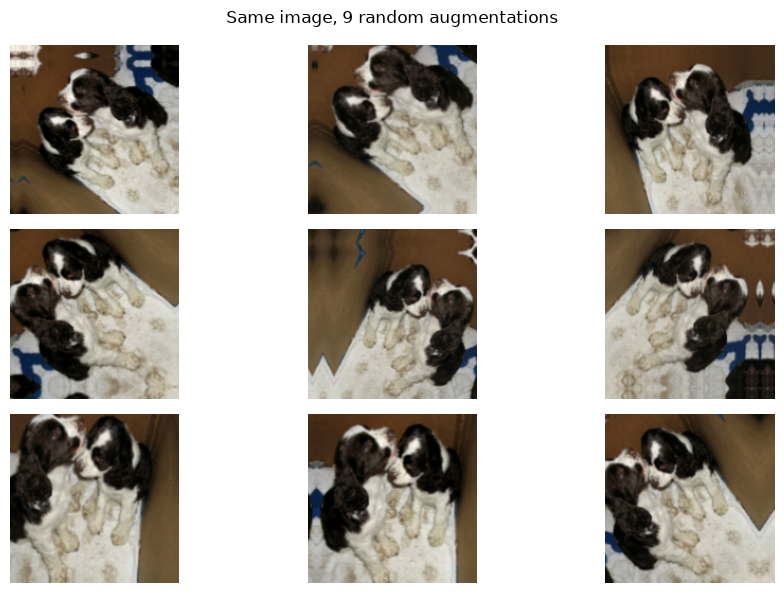

In [4]:
# Data augmentation: applied only during training (Keras disables these layers at inference)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.15),
], name="data_augmentation")

plt.figure(figsize=(10, 6))
for images, _ in train_ds.take(1):
    img = images[0:1]
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(data_augmentation(img, training=True)[0].numpy().astype("uint8")); plt.axis("off")
plt.suptitle("Same image, 9 random augmentations"); plt.tight_layout(); plt.show()

## 5. Helper functions

In [5]:
def plot_history(histories, title):
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in histories:
        acc += h.history["accuracy"]; val_acc += h.history["val_accuracy"]
        loss += h.history["loss"]; val_loss += h.history["val_loss"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val"); ax[0].set_title(title + " - accuracy"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val"); ax[1].set_title(title + " - loss"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()
    return acc, val_acc

def evaluate(model, name):
    y_true, y_pred = [], []
    for x, y in test_ds:
        y_true += y.numpy().tolist()
        y_pred += np.argmax(model.predict(x, verbose=0), axis=1).tolist()
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"\n=== {name}: test accuracy = {test_acc:.4f} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(max(4, NUM_CLASSES), max(3.5, NUM_CLASSES * 0.8)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion matrix - {name}"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()
    return float(test_acc), float(test_loss)

callbacks = lambda: [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
]

## 6. Model A: CNN from scratch (no transfer learning)

Model: "scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 424,042 (1.62 MB)

 Trainable params: 423,082 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/20


d:\ai_capstone\aicapstone\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


148/148 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.2952 - loss: 1.9880 - val_accuracy: 0.2303 - val_loss: 2.7867 - learning_rate: 0.0010
Epoch 2/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 251s 1s/step - accuracy: 0.3720 - loss: 1.7923 - val_accuracy: 0.1705 - val_loss: 2.4304 - learning_rate: 0.0010
Epoch 3/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.4269 - loss: 1.6658 - val_accuracy: 0.4230 - val_loss: 1.7802 - learning_rate: 0.0010
Epoch 4/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.4448 - loss: 1.6091 - val_accuracy: 0.5260 - val_loss: 1.4454 - learning_rate: 0.0010
Epoch 5/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 286s 2s/step - accuracy: 0.4809 - loss: 1.5369 - val_accuracy: 0.4389 - val_loss: 2.0331 - learning_rate: 0.0010
Epoch 6/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 302s 2s/step - accuracy: 0.4986 - loss: 1.4832 - val_accuracy: 0.3936 - val_loss: 2.2192 - learning_rate: 0.0010
Epoch 7/20
148/148 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.5379 - loss: 1.3901 - val_

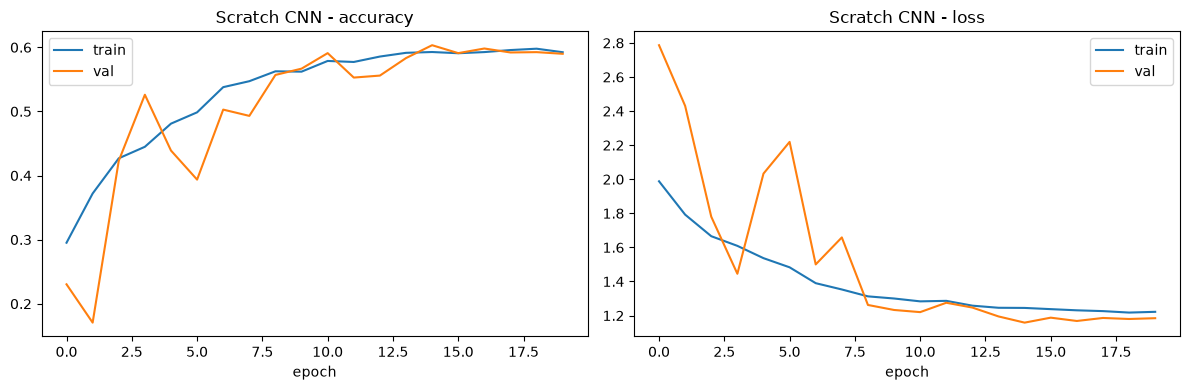


=== Scratch CNN (no transfer learning): test accuracy = 0.4531 ===
              precision    recall  f1-score   support

   n01440764     0.9296    0.5116    0.6600       387
   n02102040     0.9008    0.2759    0.4225       395
   n02979186     0.8343    0.4230    0.5613       357
   n03000684     0.5532    0.2021    0.2960       386
   n03028079     0.5278    0.8117    0.6397       409
   n03394916     0.1550    0.6200    0.2480        50
   n03417042     0.0000    0.0000    0.0000         0
   n03425413     0.0000    0.0000    0.0000         0
   n03445777     0.0000    0.0000    0.0000         0
   n03888257     0.0000    0.0000    0.0000         0

    accuracy                         0.4531      1984
   macro avg     0.3901    0.2844    0.2828      1984
weighted avg     0.7311    0.4531    0.5096      1984



d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


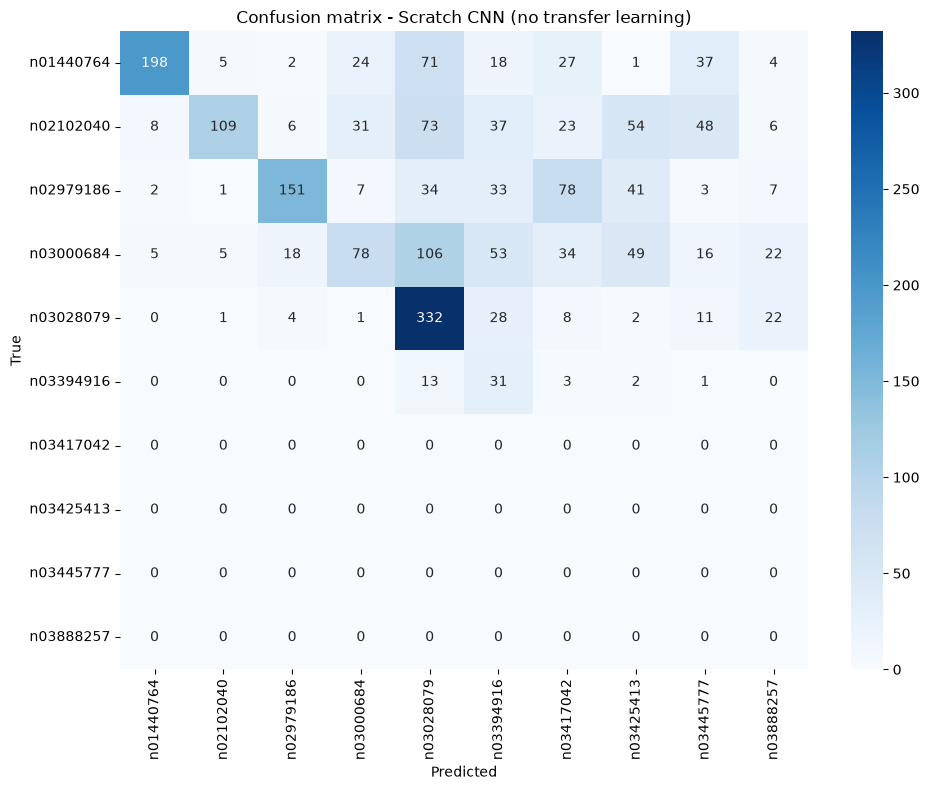

In [6]:
def build_scratch_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="scratch_cnn")

scratch_model = build_scratch_cnn()
scratch_model.summary()
scratch_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h_scratch = scratch_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_SCRATCH, callbacks=callbacks())
scratch_time = time.time() - t0
scratch_acc_curve, scratch_val_curve = plot_history([h_scratch], "Scratch CNN")
scratch_test_acc, scratch_test_loss = evaluate(scratch_model, "Scratch CNN (no transfer learning)")

## 7. Model B: MobileNetV2 transfer learning

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5


d:\ai_capstone\aicapstone\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


148/148 ━━━━━━━━━━━━━━━━━━━━ 102s 661ms/step - accuracy: 0.7867 - loss: 0.7020 - val_accuracy: 0.9742 - val_loss: 0.1098 - learning_rate: 0.0010
Epoch 2/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 96s 649ms/step - accuracy: 0.8962 - loss: 0.3315 - val_accuracy: 0.9820 - val_loss: 0.0667 - learning_rate: 0.0010
Epoch 3/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 98s 660ms/step - accuracy: 0.9076 - loss: 0.2798 - val_accuracy: 0.9820 - val_loss: 0.0595 - learning_rate: 0.0010
Epoch 4/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 101s 679ms/step - accuracy: 0.9161 - loss: 0.2623 - val_accuracy: 0.9840 - val_loss: 0.0504 - learning_rate: 0.0010
Epoch 5/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 104s 701ms/step - accuracy: 0.9247 - loss: 0.2387 - val_accuracy: 0.9851 - val_loss: 0.0476 - learning_rate: 0.0010
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 118s 767ms/step - accuracy: 0.9266 - loss: 0.2262 - val_accuracy: 0.9830 - val_loss: 0.0533 - learning_rate: 1.0000e-05
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 115s 777ms/step - accuracy: 0.9295 - 

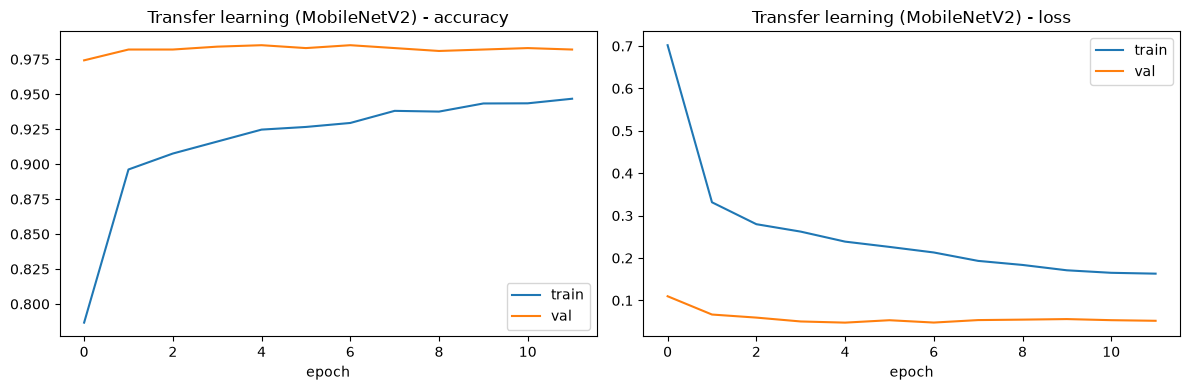


=== MobileNetV2 transfer learning: test accuracy = 0.9783 ===
              precision    recall  f1-score   support

   n01440764     1.0000    0.9922    0.9961       387
   n02102040     0.9949    0.9949    0.9949       395
   n02979186     0.9830    0.9720    0.9775       357
   n03000684     1.0000    0.9404    0.9693       386
   n03028079     0.9951    0.9902    0.9926       409
   n03394916     0.8033    0.9800    0.8829        50
   n03417042     0.0000    0.0000    0.0000         0
   n03425413     0.0000    0.0000    0.0000         0
   n03445777     0.0000    0.0000    0.0000         0
   n03888257     0.0000    0.0000    0.0000         0

    accuracy                         0.9783      1984
   macro avg     0.5776    0.5870    0.5813      1984
weighted avg     0.9900    0.9783    0.9837      1984



d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ai_capstone\aicapstone\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


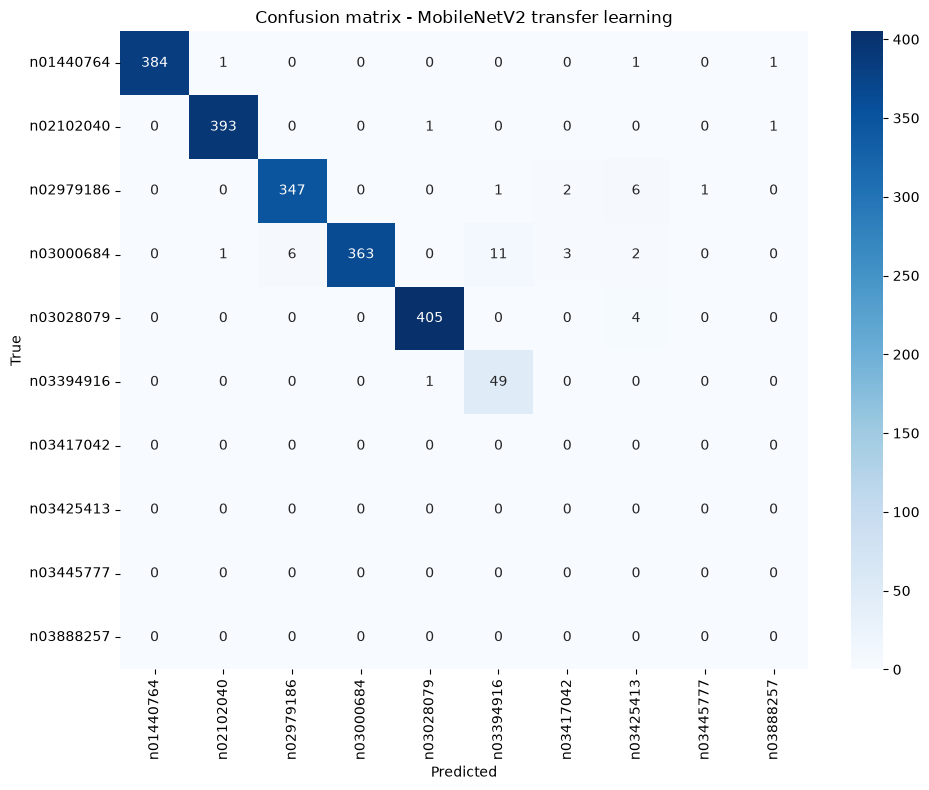

In [7]:
def build_transfer_model():
    base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)   # scales to [-1, 1]
    x = base(x, training=False)                                # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base

tl_model, base_model = build_transfer_model()
tl_model.summary()

# Stage 1: feature extraction (frozen backbone, train the new classifier head)
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h_head = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks())

# Stage 2: fine-tuning (unfreeze the top ~30 layers with a small learning rate)
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
tl_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_fine = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD + EPOCHS_FINE, initial_epoch=len(h_head.epoch), callbacks=callbacks())
tl_time = time.time() - t0

tl_acc_curve, tl_val_curve = plot_history([h_head, h_fine], "Transfer learning (MobileNetV2)")
tl_test_acc, tl_test_loss = evaluate(tl_model, "MobileNetV2 transfer learning")

## 8. Comparison: with vs. without transfer learning

,Metric,Without transfer learning (scratch CNN),With transfer learning (MobileNetV2)
0,Test accuracy,0.4531,9.783000e-01
1,Test loss,1.6427,6.380000e-02
2,Best val accuracy,0.6033,9.851000e-01
3,Epochs run,20.0000,1.200000e+01
4,Training time (s),5213.5620,1.629668e+03
5,Total parameters,424042.0000,2.270794e+06


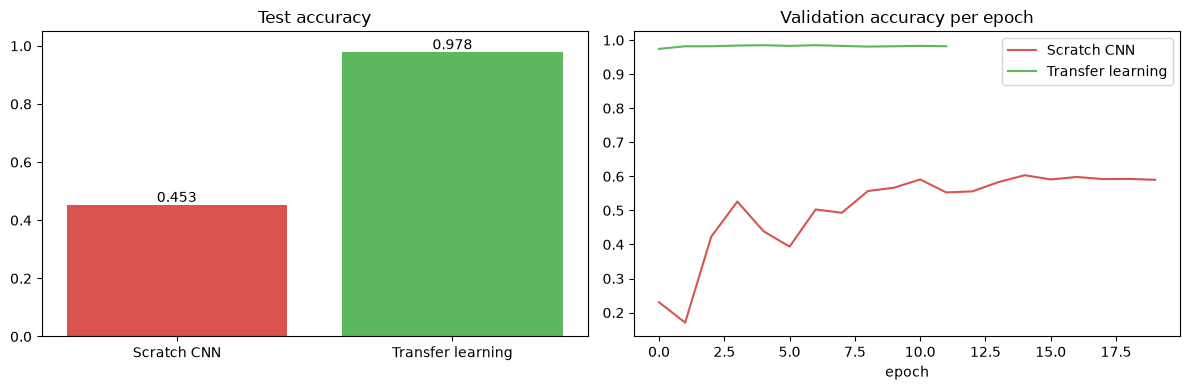

Transfer learning changed test accuracy by +52.52 percentage points vs. training from scratch.


In [8]:
results = {
    "project": "imagenet10",
    "title": "PRAICP-1010: Image Classification on 10 Categories",
    "num_classes": NUM_CLASSES,
    "scratch": {"test_acc": scratch_test_acc, "test_loss": scratch_test_loss, "best_val_acc": float(max(scratch_val_curve)),
                "epochs_run": len(scratch_acc_curve), "train_time_s": scratch_time, "params": int(scratch_model.count_params())},
    "transfer": {"test_acc": tl_test_acc, "test_loss": tl_test_loss, "best_val_acc": float(max(tl_val_curve)),
                 "epochs_run": len(tl_acc_curve), "train_time_s": tl_time, "params": int(tl_model.count_params())},
}
os.makedirs("results", exist_ok=True)
with open("results/imagenet10.json", "w") as f:
    json.dump(results, f, indent=2)

import pandas as pd
df = pd.DataFrame({
    "Metric": ["Test accuracy", "Test loss", "Best val accuracy", "Epochs run", "Training time (s)", "Total parameters"],
    "Without transfer learning (scratch CNN)": [results["scratch"][k] for k in ("test_acc", "test_loss", "best_val_acc", "epochs_run", "train_time_s", "params")],
    "With transfer learning (MobileNetV2)": [results["transfer"][k] for k in ("test_acc", "test_loss", "best_val_acc", "epochs_run", "train_time_s", "params")],
})
display(df.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Scratch CNN", "Transfer learning"], [scratch_test_acc, tl_test_acc], color=["#d9534f", "#5cb85c"])
ax[0].set_ylim(0, 1.05); ax[0].set_title("Test accuracy")
for i, v in enumerate([scratch_test_acc, tl_test_acc]): ax[0].text(i, v + 0.01, f"{v:.3f}", ha="center")
ax[1].plot(scratch_val_curve, label="Scratch CNN", color="#d9534f"); ax[1].plot(tl_val_curve, label="Transfer learning", color="#5cb85c")
ax[1].set_title("Validation accuracy per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

gain = (tl_test_acc - scratch_test_acc) * 100
print(f"Transfer learning changed test accuracy by {gain:+.2f} percentage points vs. training from scratch.")

## 9. Conclusion
####### This project compared a custom CNN trained from scratch against a transfer-learning model (MobileNetV2), both using data augmentation, to classify images into 10 categories. The scratch CNN reached only 45.31% test accuracy with a test loss of 1.6427. MobileNetV2 reached 97.83% test accuracy with a test loss of 0.0638, an improvement of about 52 percentage points. It also trained about 3 times faster (about 27 minutes vs 87) and needed fewer epochs (12 vs 20), because it reuses features already learned from ImageNet, while the scratch CNN could not learn enough from a small dataset. Transfer learning with MobileNetV2 is therefore the clearly better and more efficient choice for this task, and future work could try fine-tuning more layers, larger backbones such as EfficientNet or ResNet, and a larger dataset.